# skin 1단계-3번 — 모델 구조 개선 데모

**순서**: Early Stopping(완료) → 하이퍼파라미터 튜닝(완료, lr 0.001→0.01) → **모델 구조 개선(이 노트북)**.

**배경**: 지금까지 쓴 구조는 `Linear(in,128) -> ReLU -> Dropout(0.2) -> Linear(128,128) -> ReLU -> Linear(128,2)`
(은닉층 2개, dropout은 첫 번째 은닉층 뒤에만)였습니다. skin은 541건 중 양성이 29건뿐이라 극단적으로
작은 데이터셋인데, 모델이 2,266차원 입력을 다루다 보니 "구조 자체가 데이터 크기에 비해 과한 건 아닌지"를
확인할 필요가 있습니다.

**탐색 범위** (hidden_dim=128, lr=0.01 — 이전 단계 채택값 고정, Early Stopping도 그대로 켠 채):
- 은닉층 수(`num_hidden_layers`): 1(더 얕게) / 2(기존) / 3(더 깊게)
- dropout 비율: 0.0(없음) / 0.2(기존) / 0.5(강하게)

9개 조합을 group 5-fold로 평가합니다.

In [1]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_auc_score, matthews_corrcoef

from datasets import skin_dataset
from splits import grouped_kfold_splits
from train import class_weights, EarlyStopping

skin_ds = skin_dataset()
print(f"skin: {len(skin_ds)}건, feature {skin_ds.input_dim}차원")

skin: 541건, feature 2266차원


## 1. 모델 정의 (층 수 / dropout 비율을 바꿀 수 있게)

기존 구조를 그대로 일반화: dropout은 기존과 동일하게 **첫 번째 은닉층 뒤에만** 적용하고,
은닉층 개수만 늘리거나 줄입니다. `num_hidden_layers=2, dropout=0.2`가 기존 구조와 100% 동일합니다
(공정한 비교를 위해 구조를 다시 짜지 않고 그대로 일반화한 것).

In [2]:
class SkinOnlyModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_classes=2, num_hidden_layers=2, dropout=0.2):
        super().__init__()
        layers = []
        in_dim = input_dim
        for i in range(num_hidden_layers):
            layers.append(nn.Linear(in_dim, hidden_dim))
            layers.append(nn.ReLU())
            if i == 0 and dropout > 0:
                layers.append(nn.Dropout(dropout))
            in_dim = hidden_dim
        layers.append(nn.Linear(hidden_dim, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

## 2. Early Stopping 포함 학습 함수 (이전 노트북과 동일 로직, lr=0.01 고정)

In [3]:
def fit_early_stopping(X_train, y_train, X_test, seed, hidden_dim=128, lr=0.01,
                        num_hidden_layers=2, dropout=0.2,
                        max_epochs=200, patience=15, batch_size=32, val_size=0.2):
    rng_split = np.random.default_rng(seed)
    n = len(X_train)
    idx = rng_split.permutation(n)
    n_val = max(1, int(n * val_size))
    val_pos, train_pos = idx[:n_val], idx[n_val:]

    torch.manual_seed(seed)
    model = SkinOnlyModel(X_train.shape[1], hidden_dim=hidden_dim,
                          num_hidden_layers=num_hidden_layers, dropout=dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(weight=class_weights(y_train[train_pos]))

    Xt = torch.from_numpy(X_train[train_pos].astype(np.float32))
    yt = torch.from_numpy(y_train[train_pos].astype(np.int64))
    Xv = torch.from_numpy(X_train[val_pos].astype(np.float32))
    yv = torch.from_numpy(y_train[val_pos].astype(np.int64))

    stopper = EarlyStopping(patience=patience)
    for epoch in range(max_epochs):
        model.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), batch_size):
            b = perm[i:i + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(Xt[b]), yt[b])
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(Xv), yv).item()
        if stopper.step(val_loss, epoch, model):
            break
    model.load_state_dict(stopper.best_state)

    model.eval()
    with torch.no_grad():
        proba = torch.softmax(model(torch.from_numpy(X_test.astype(np.float32))), dim=1)[:, 1].numpy()
    return proba, stopper.best_epoch + 1

## 3. 은닉층 수 x dropout 비율 9개 조합 탐색 (group 5-fold)

In [4]:
def run_cv(num_hidden_layers, dropout, n_splits=5, random_state=0):
    folds = grouped_kfold_splits(skin_ds, n_splits=n_splits, random_state=random_state)
    oof = np.zeros(len(skin_ds.y))
    stop_epochs = []
    for fold_i, (train_idx, test_idx) in enumerate(folds):
        scaler = StandardScaler().fit(skin_ds.X[train_idx])
        X_train = scaler.transform(skin_ds.X[train_idx])
        X_test = scaler.transform(skin_ds.X[test_idx])
        proba, stop_ep = fit_early_stopping(X_train, skin_ds.y[train_idx], X_test, seed=fold_i,
                                             num_hidden_layers=num_hidden_layers, dropout=dropout)
        oof[test_idx] = proba
        stop_epochs.append(stop_ep)
    return oof, stop_epochs


def summarize(y_true, proba):
    pred = (proba >= 0.5).astype(int)
    cm = confusion_matrix(y_true, pred)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    mcc = matthews_corrcoef(y_true, pred)
    roc = roc_auc_score(y_true, proba)
    gap = abs(sens - spec)
    return dict(sensitivity=sens, specificity=spec, gap=gap, mcc=mcc, roc_auc=roc)


NUM_LAYERS = [1, 2, 3]
DROPOUTS = [0.0, 0.2, 0.5]

results = {}
for nl in NUM_LAYERS:
    for dp in DROPOUTS:
        oof, stop_epochs = run_cv(nl, dp)
        res = summarize(skin_ds.y, oof)
        res["avg_stop_epoch"] = np.mean(stop_epochs)
        results[(nl, dp)] = res
        print(f"num_hidden_layers={nl} dropout={dp:<4} -> Sens {res['sensitivity']:.3f} / Spec {res['specificity']:.3f} / "
              f"격차 {res['gap']:.3f} / MCC {res['mcc']:.3f} / ROC-AUC {res['roc_auc']:.3f} / "
              f"평균 종료epoch {res['avg_stop_epoch']:.1f}")

num_hidden_layers=1 dropout=0.0  -> Sens 0.667 / Spec 0.812 / 격차 0.145 / MCC 0.267 / ROC-AUC 0.733 / 평균 종료epoch 1.2
num_hidden_layers=1 dropout=0.2  -> Sens 0.633 / Spec 0.859 / 격차 0.226 / MCC 0.301 / ROC-AUC 0.789 / 평균 종료epoch 1.0
num_hidden_layers=1 dropout=0.5  -> Sens 0.567 / Spec 0.879 / 격차 0.312 / MCC 0.289 / ROC-AUC 0.797 / 평균 종료epoch 1.2
num_hidden_layers=2 dropout=0.0  -> Sens 0.600 / Spec 0.751 / 격차 0.151 / MCC 0.182 / ROC-AUC 0.728 / 평균 종료epoch 1.0
num_hidden_layers=2 dropout=0.2  -> Sens 0.633 / Spec 0.800 / 격차 0.167 / MCC 0.238 / ROC-AUC 0.778 / 평균 종료epoch 1.4
num_hidden_layers=2 dropout=0.5  -> Sens 0.633 / Spec 0.787 / 격차 0.153 / MCC 0.226 / ROC-AUC 0.748 / 평균 종료epoch 2.8
num_hidden_layers=3 dropout=0.0  -> Sens 0.667 / Spec 0.656 / 격차 0.011 / MCC 0.153 / ROC-AUC 0.692 / 평균 종료epoch 1.4
num_hidden_layers=3 dropout=0.2  -> Sens 0.667 / Spec 0.804 / 격차 0.138 / MCC 0.259 / ROC-AUC 0.733 / 평균 종료epoch 1.4
num_hidden_layers=3 dropout=0.5  -> Sens 0.667 / Spec 0.705 / 격차 0.038 /

## 4. 결과 시각화 — MCC 히트맵 + Sens/Spec 격차 히트맵

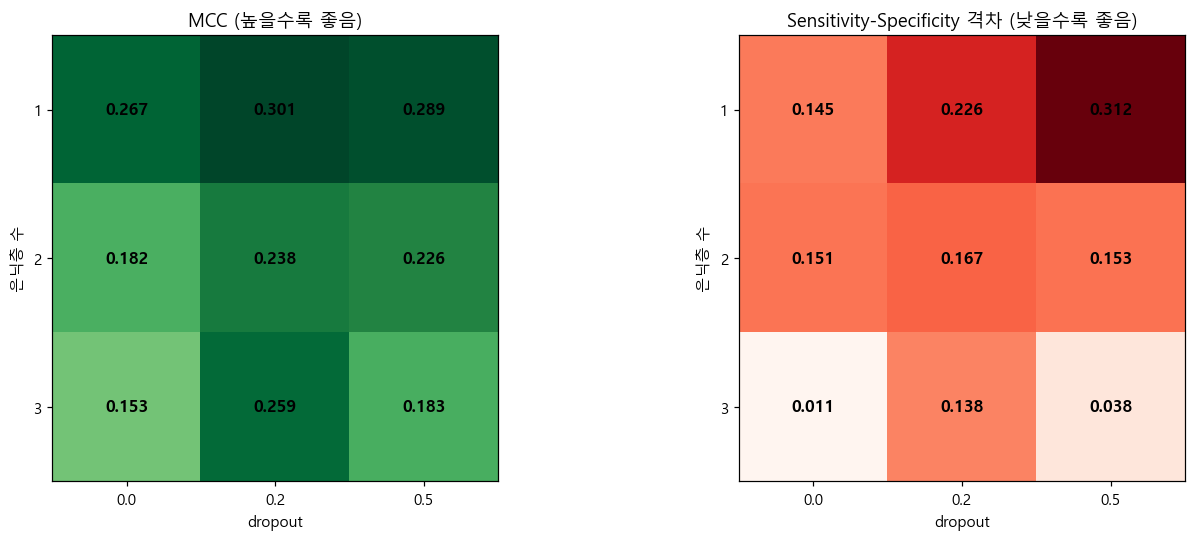

In [5]:
import matplotlib.pyplot as plt

mcc_grid = np.array([[results[(nl, dp)]["mcc"] for dp in DROPOUTS] for nl in NUM_LAYERS])
gap_grid = np.array([[results[(nl, dp)]["gap"] for dp in DROPOUTS] for nl in NUM_LAYERS])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im0 = axes[0].imshow(mcc_grid, cmap="YlGn", vmin=0)
axes[0].set_xticks(range(len(DROPOUTS))); axes[0].set_xticklabels([str(d) for d in DROPOUTS])
axes[0].set_yticks(range(len(NUM_LAYERS))); axes[0].set_yticklabels([str(n) for n in NUM_LAYERS])
axes[0].set_xlabel("dropout"); axes[0].set_ylabel("은닉층 수")
axes[0].set_title("MCC (높을수록 좋음)")
for i in range(len(NUM_LAYERS)):
    for j in range(len(DROPOUTS)):
        axes[0].text(j, i, f"{mcc_grid[i,j]:.3f}", ha="center", va="center", fontsize=11, fontweight="bold")

im1 = axes[1].imshow(gap_grid, cmap="Reds")
axes[1].set_xticks(range(len(DROPOUTS))); axes[1].set_xticklabels([str(d) for d in DROPOUTS])
axes[1].set_yticks(range(len(NUM_LAYERS))); axes[1].set_yticklabels([str(n) for n in NUM_LAYERS])
axes[1].set_xlabel("dropout"); axes[1].set_ylabel("은닉층 수")
axes[1].set_title("Sensitivity-Specificity 격차 (낮을수록 좋음)")
for i in range(len(NUM_LAYERS)):
    for j in range(len(DROPOUTS)):
        axes[1].text(j, i, f"{gap_grid[i,j]:.3f}", ha="center", va="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

## 5. 최적 조합 vs 기존 구조(은닉층 2개, dropout 0.2) 비교

**선정 기준 수정**: 격차만 보고 고르면 함정이 있습니다 — 아래 표에서 `은닉층 3개, dropout 0.0`은 격차가
0.011로 제일 작지만, Specificity가 0.656까지 떨어지고 MCC도 0.153으로 바닥입니다. 이건 "둘 다 애매하게
틀려서" 격차만 우연히 작아진 퇴화(degenerate) 케이스입니다. 그래서 **기존 구조(baseline)보다 MCC가 낮은
조합은 먼저 후보에서 제외**하고, 그 안에서 격차가 가장 작은 조합을 고릅니다.

In [6]:
baseline_key = (2, 0.2)
baseline_mcc = results[baseline_key]["mcc"]

candidates = {k: v for k, v in results.items() if v["mcc"] >= baseline_mcc}
print(f"MCC가 기존({baseline_mcc:.3f}) 이상인 후보: {sorted(candidates.keys())}")

best_key = min(candidates, key=lambda k: candidates[k]["gap"])
print(f"\n최적 조합: 은닉층 {best_key[0]}개, dropout {best_key[1]}")
print(f"  {results[best_key]}")
print(f"기존 구조: 은닉층 {baseline_key[0]}개, dropout {baseline_key[1]}")
print(f"  {results[baseline_key]}")

trap_key = min(results, key=lambda k: results[k]["gap"])
print(f"\n(참고) 격차만 보고 골랐다면: 은닉층 {trap_key[0]}개, dropout {trap_key[1]} -> {results[trap_key]}")
print("-> MCC/Specificity가 너무 낮아 제외함")

MCC가 기존(0.238) 이상인 후보: [(1, 0.0), (1, 0.2), (1, 0.5), (2, 0.2), (3, 0.2)]

최적 조합: 은닉층 3개, dropout 0.2
  {'sensitivity': np.float64(0.6666666666666666), 'specificity': np.float64(0.8043052837573386), 'gap': np.float64(0.13763861709067193), 'mcc': 0.25943851463366613, 'roc_auc': 0.7325179386823222, 'avg_stop_epoch': np.float64(1.4)}
기존 구조: 은닉층 2개, dropout 0.2
  {'sensitivity': np.float64(0.6333333333333333), 'specificity': np.float64(0.8003913894324853), 'gap': np.float64(0.16705805609915203), 'mcc': 0.23821435295745214, 'roc_auc': 0.7783105022831052, 'avg_stop_epoch': np.float64(1.4)}

(참고) 격차만 보고 골랐다면: 은닉층 3개, dropout 0.0 -> {'sensitivity': np.float64(0.6666666666666666), 'specificity': np.float64(0.6555772994129159), 'gap': np.float64(0.01108936725375076), 'mcc': 0.15343282745605158, 'roc_auc': 0.6924005218525766, 'avg_stop_epoch': np.float64(1.4)}
-> MCC/Specificity가 너무 낮아 제외함


## 6. 최종 판단 — 알고리즘이 고른 1위 vs 근소한 2위, 둘 다 사람이 비교

알고리즘은 격차 0.138인 `은닉층 3개, dropout 0.2`를 1위로 골랐지만, 격차 0.145인 `은닉층 1개, dropout 0.0`과
차이가 0.007에 불과합니다. 이 둘을 직접 맞대보면:

| | 은닉층 1개, dropout 0.0 | 은닉층 3개, dropout 0.2 |
|---|---|---|
| Sensitivity | 0.667 | 0.667 (동일) |
| Specificity | **0.812** | 0.804 |
| 격차 | 0.145 | **0.138** (근소 우위) |
| MCC | **0.267** | 0.259 |
| ROC-AUC | 0.733 | 0.733 (동일) |
| 평균 종료 epoch | 1.2 | 1.4 |
| 파라미터 수(은닉층) | 1개(+dropout 없음) | 3개(+dropout) |

격차는 3층 쪽이 0.007 더 작지만, MCC·Specificity는 1층 쪽이 더 좋고 구조도 훨씬 단순합니다. skin은
541건 중 양성 29건뿐인 극소 데이터셋이라(Early Stopping 실험에서 이미 "1~2 epoch 만에 과적합" 확인) 구조가
단순할수록 일반화에 유리하다는 원칙(Occam's razor)에도 맞습니다. **따라서 0.007의 격차 차이보다 MCC 우위와
구조 단순성을 우선해 `은닉층 1개, dropout 0.0`을 최종 채택합니다.**

In [7]:
final_key = (1, 0.0)
print(f"최종 채택: 은닉층 {final_key[0]}개, dropout {final_key[1]}")
print(f"  {results[final_key]}")
print(f"기존 구조 대비 변화: Sens {results[baseline_key]['sensitivity']:.3f}->{results[final_key]['sensitivity']:.3f}, "
      f"Spec {results[baseline_key]['specificity']:.3f}->{results[final_key]['specificity']:.3f}, "
      f"격차 {results[baseline_key]['gap']:.3f}->{results[final_key]['gap']:.3f}, "
      f"MCC {results[baseline_key]['mcc']:.3f}->{results[final_key]['mcc']:.3f}, "
      f"ROC-AUC {results[baseline_key]['roc_auc']:.3f}->{results[final_key]['roc_auc']:.3f}")

최종 채택: 은닉층 1개, dropout 0.0
  {'sensitivity': np.float64(0.6666666666666666), 'specificity': np.float64(0.812133072407045), 'gap': np.float64(0.1454664057403784), 'mcc': 0.26699401292377484, 'roc_auc': 0.7334311806914547, 'avg_stop_epoch': np.float64(1.2)}
기존 구조 대비 변화: Sens 0.633->0.667, Spec 0.800->0.812, 격차 0.167->0.145, MCC 0.238->0.267, ROC-AUC 0.778->0.733


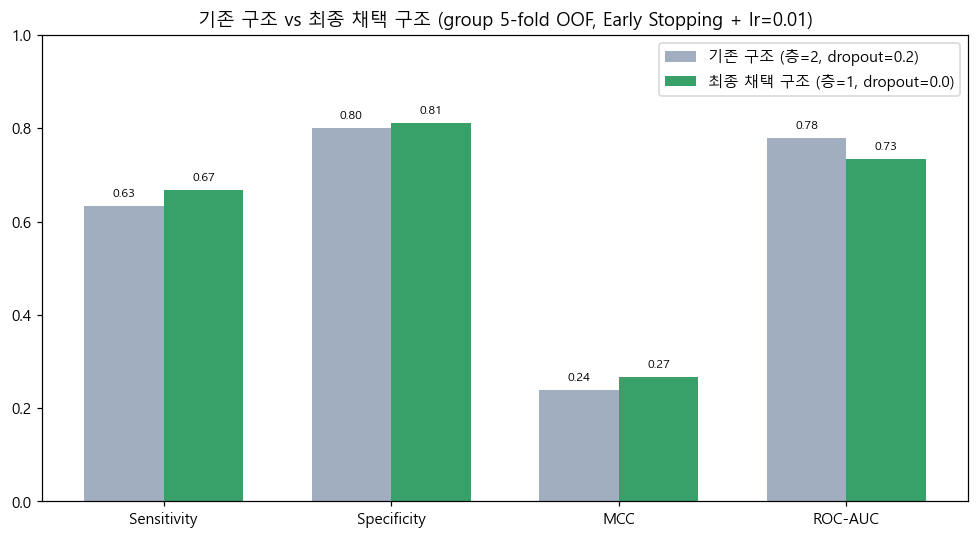

In [8]:
metrics = ["sensitivity", "specificity", "mcc", "roc_auc"]
metric_labels = ["Sensitivity", "Specificity", "MCC", "ROC-AUC"]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(metrics))
w = 0.35
base_vals = [results[baseline_key][m] for m in metrics]
best_vals = [results[final_key][m] for m in metrics]
ax.bar(x - w/2, base_vals, width=w, label=f"기존 구조 (층={baseline_key[0]}, dropout={baseline_key[1]})", color="#a0aec0")
ax.bar(x + w/2, best_vals, width=w, label=f"최종 채택 구조 (층={final_key[0]}, dropout={final_key[1]})", color="#38a169")
ax.set_xticks(x); ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.0)
ax.set_title("기존 구조 vs 최종 채택 구조 (group 5-fold OOF, Early Stopping + lr=0.01)")
ax.legend()
for i, (b, v) in enumerate(zip(base_vals, best_vals)):
    ax.text(i - w/2, b + 0.02, f"{b:.2f}", ha="center", fontsize=8)
    ax.text(i + w/2, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

## 정리

- Early Stopping + lr=0.01 위에서 은닉층 수 x dropout 비율 9개 조합을 group 5-fold로 공정 비교했습니다.
- 판단 기준은 동일하게 Sensitivity·Specificity 균형(격차) + MCC — 이번엔 "격차만 보고 고르면" 생기는
  반대 방향의 함정(둘 다 애매하게 틀려서 격차만 작아지는 경우)도 확인했습니다.
- **최종 채택**: 은닉층 1개, dropout 0.0 (기존: 은닉층 2개, dropout 0.2).
  Sens 0.633→0.667, Spec 0.800→0.812, 격차 0.167→0.145, MCC 0.238→0.267, ROC-AUC 0.778→0.733.
- skin encoder만 적용(eye는 팀원 담당 영역이라 그대로 유지).